# 07 · The dashboard: a browser twin of THE world

**What you will see**
- `Dashboard(sim)` serving the SO-101 + G1 world on loopback (port 8742).
- Headless Chromium opening the page; MuJoCo compiled to WebAssembly paints both robots from `/api/scene`.
- A server-side `act` (POST `/api/robots/so101/act`) moving the arm in the page.
- The keys of `/api/scene`, then a clean stop.

The dashboard holds a reference to the world, not a copy. Every read takes `sim.lock`, so a robot added from Python shows up on the page with nothing to sync.

In [1]:
import _nb
_nb.drawing('v07_dashboard')

## Serve the world

In [2]:
from strands_robots import Robot, Simulation
from strands_robots.dashboard import Dashboard

sim = Simulation()
arm = Robot("so101", sim=sim)
g1 = Robot("unitree_g1", sim=sim, position=[1.0, 0.0, 0.0])
server = Dashboard(sim).start(port=8742)  # uvicorn in a background thread, loopback only
print(server.url)

http://127.0.0.1:8742


## Open it in headless Chromium

Playwright's sync API refuses to run inside Jupyter's asyncio loop, so the browser lives on its own thread. WebGL runs through SwiftShader (software). Compiling the humanoid in the browser takes a few seconds.

integrator: parent has 0 (default), child has 3, keeping parent value



{'painted_s': 9.9, 'error': None, 'so101_joints': 7, 'g1_joints': 30, 'frames': 18, 'page_errors': []}


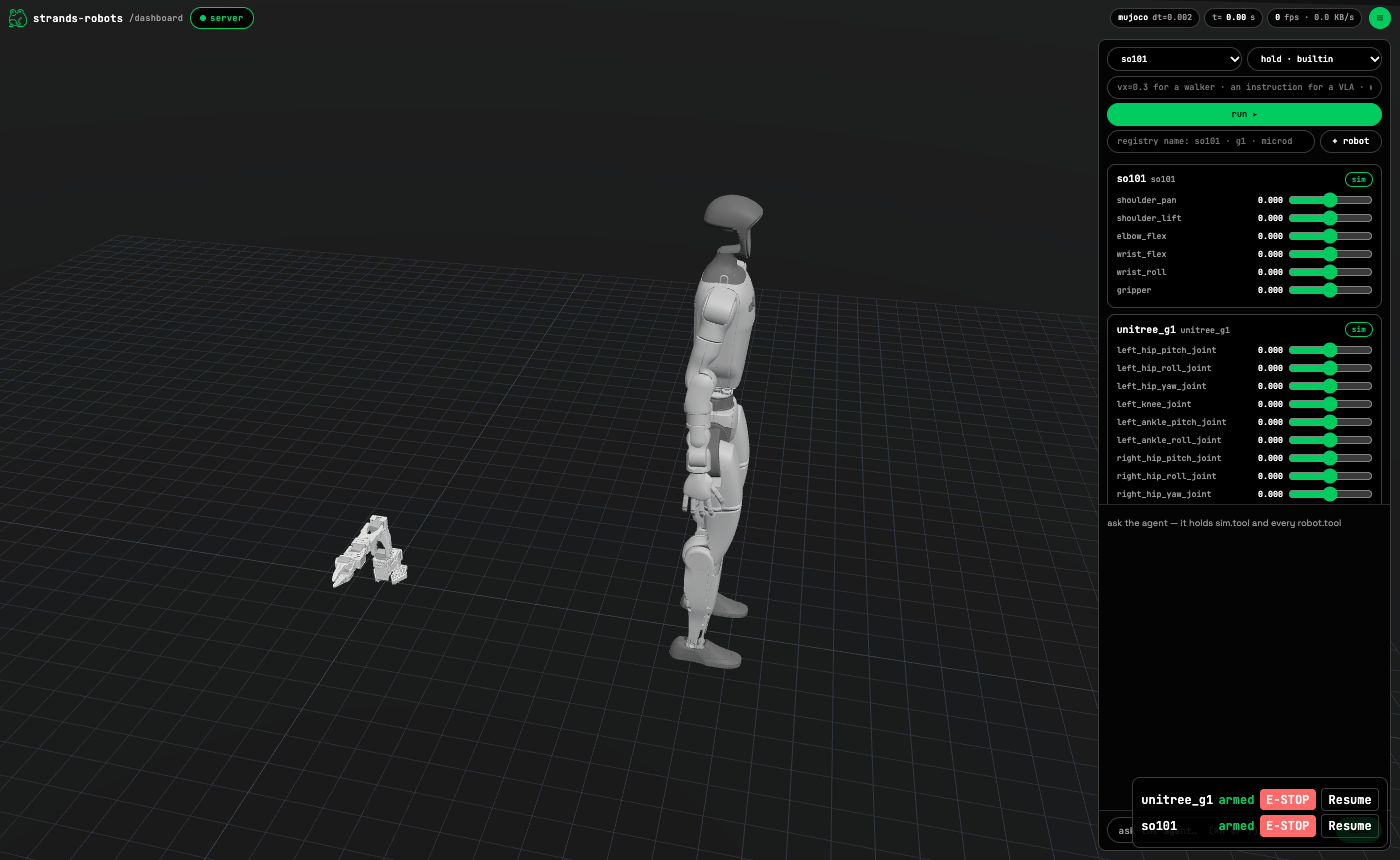

In [3]:
import queue, threading, time
from IPython.display import Image, display

jobs, done = queue.Queue(), queue.Queue()


def browser_thread(url):
    from playwright.sync_api import sync_playwright
    with sync_playwright() as p:
        browser = p.chromium.launch(args=["--use-gl=angle", "--use-angle=swiftshader", "--enable-unsafe-swiftshader"])
        page = browser.new_page(viewport={"width": 1400, "height": 860})
        errors = []
        page.on("pageerror", lambda e: errors.append(str(e)))
        try:
            page.goto(url)
            while (job := jobs.get()) is not None:
                try:
                    done.put(("ok", job(page, errors)))
                except Exception as exc:  # noqa: BLE001
                    done.put(("err", exc))
        finally:
            browser.close()


def in_browser(fn, timeout=120):
    jobs.put(fn)
    kind, value = done.get(timeout=timeout)
    if kind == "err":
        raise value
    return value


bt = threading.Thread(target=browser_thread, args=(server.url,), daemon=True)
bt.start()


def wait_painted(page, errors):
    t0 = time.perf_counter()
    page.wait_for_function("window.__sceneLoaded >= 1 || window.__error", timeout=90_000)
    page.wait_for_function("window.__twin && window.__twin.frames > 5", timeout=30_000)
    names = page.evaluate("window.__twin.model.jnt_names")
    return {"painted_s": round(time.perf_counter() - t0, 1), "error": page.evaluate("window.__error || null"),
            "so101_joints": sum(n.startswith("so101/") for n in names),
            "g1_joints": sum(n.startswith("unitree_g1/") for n in names),
            "frames": page.evaluate("window.__twin.frames"), "page_errors": list(errors)}


print(in_browser(wait_painted))
display(Image(in_browser(lambda page, errors: page.screenshot()), width=900))

## A server-side act shows up in the twin

Each POST is one control step toward the targets (the way a slider streams commands). The page's own `fetch` sends 80 same-origin JSON POSTs (the guard refuses cross-site requests and non-JSON POSTs). The server runs `confirm_act` through the robot's safety chain. A simulated body needs no `X-Confirm`.

80 POSTs, last HTTP 200 {'shoulder_pan': 1.202, 'shoulder_lift': -0.786, 'elbow_flex': 0.927, 'wrist_flex': 0.128, 'wrist_roll': 0.0, 'gripper': -0.0}
server-side shoulder_pan: 1.202


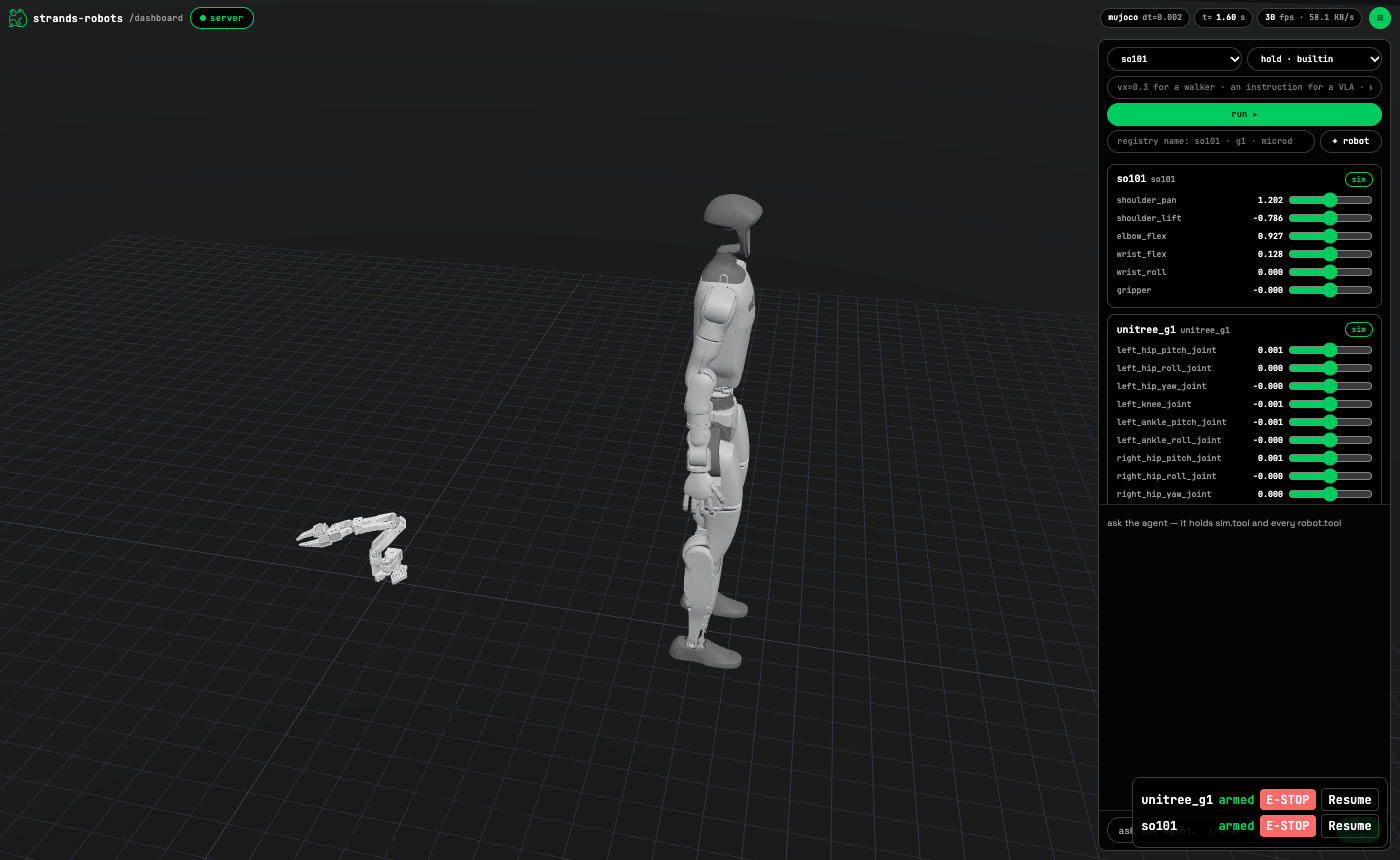

In [4]:
def act_from_page(page, errors):
    r = page.evaluate("""async () => {
        let r, n = 0;
        for (; n < 80; n++) {  // one control step per POST, like a slider being dragged
            r = await fetch('/api/robots/so101/act', {method: 'POST', headers: {'Content-Type': 'application/json'},
                body: JSON.stringify({targets: {shoulder_pan: 1.2, shoulder_lift: -0.8, elbow_flex: 0.9}})});
        }
        return {posts: n, status: r.status, body: await r.json()};
    }""")
    f0 = page.evaluate("window.__twin.frames")
    page.wait_for_function(f"window.__twin.frames > {f0 + 10}", timeout=20_000)
    return r


r = in_browser(act_from_page)
print(r["posts"], "POSTs, last HTTP", r["status"], {k: round(v, 3) for k, v in r["body"]["joints"].items()})
print("server-side shoulder_pan:", round(arm.observe(images=False)["shoulder_pan"], 3))
display(Image(in_browser(lambda page, errors: page.screenshot()), width=900))

## `/api/scene`: what the page is built from

In [5]:
import json, urllib.request

scene = json.load(urllib.request.urlopen(server.url + "/api/scene"))
print(sorted(scene))
print("robots:", [(c.get("id"), len(c.get("action_keys", c.get("joints", [])))) for c in scene["robots"]])
print("physics:", scene["physics"], "| stats:", scene["stats"], "| assets:", len(scene["assets"]), "| xml chars:", len(scene["xml"]))

['assets', 'objects', 'physics', 'revision', 'robots', 'stats', 'time', 'xml']
robots: [('so101', 6), ('unitree_g1', 29)]
physics: {'name': 'mujoco', 'timestep': 0.002, 'substeps': 10, 'backend': 'mujoco'} | stats: {'nq': 49, 'nu': 35, 'ngeom': 102, 'nmesh': 48, 'nbody': 39} | assets: 48 | xml chars: 44111


## Stop everything

In [6]:
jobs.put(None); bt.join(timeout=30)
server.stop()
sim.close()
import socket
with socket.socket() as s:
    print("browser stopped:", not bt.is_alive(), "| port 8742 free:", s.connect_ex(("127.0.0.1", 8742)) != 0)

browser stopped: True | port 8742 free: True


## A real leader arm driving the twin

`notebooks/examples/leader_twin.py` reads a real **SO-101 leader** arm over USB with LeRobot (read only, torque off), at about **26 Hz**. It converts its degrees to radians through strands' `lerobot` units scheme and calls `arm.act(q)` on the simulated SO-101, while `Dashboard(arm.sim).serve(port=8095)` shows it. Moving the leader by hand moves the twin in the browser. It isn't run here because it needs the arm plugged in.

## Where this sits in v1
- **Part 10 (dashboard):** `Dashboard(sim, robots=..., model=..., mesh=...)`. The routes are `/api/scene`, `/ws/state`, `act`/`run`/`stop`/`estop`/`resume`, runtime `POST /api/robots`, and a chat panel over the tools from 06.
- It's guarded on loopback: same Host and Origin, JSON-only POSTs. A real body needs `X-Confirm`, and e-stop latches until a named resume.
- MuJoCo WASM 3.14 + three.js r170 are vendored with sha256 pins, and FastAPI/uvicorn are imported only by the dashboard.